In [1]:
from mercupix.ramp import RawRamp
from mercupix.rampfit import get_ramp_fit, Kubik2015
from mercupix.image import SciExposure
import matplotlib.pyplot as plt
import numpy as np

### Read raw ramp and "process"

In [2]:
ramp = RawRamp.from_filename('/ip2i/lyoeuclidsrv04/data1/euclid/IP2I/Setup_Euclid/OT/L0/RUN012/100K/1760768792.18-20251023_02h28_21-ip2i:la_led1_1900aduf_1f17_3spectro_r15-asic_01-acq.h5',
                  frame_path='/run/seq_1/asic_1/ramp_1/frames',
                   time_arr_path='/run/seq_1/env_measures/')

# To be tested with Roman triplet data as well. Some header measurement needed mostlikely.

Plot : 

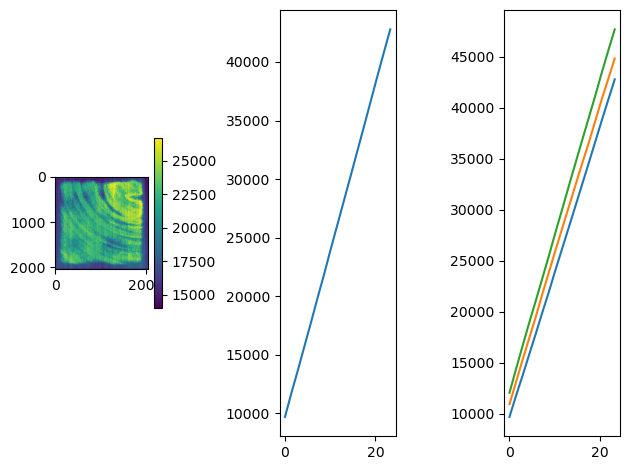

In [3]:
fig, axs = plt.subplots(1,3)
fig = ramp.show_frame(frame_num=3, fig=fig, ax=axs[0]) # Frame to be chosen, default to 0
fig = ramp.show_pixramp(pixel_num=2040*10, fig=fig, ax=axs[1])  # Example get one ramp for a single pixel. 
fig = ramp.show_pixramp(pixel_num=(2040*10, 2040*(2040-1000), 2040*(2040-2121)), fig=fig, ax=axs[2])  # Example get one ramp for several pixel. 
# Small issue with axes sizes.
plt.tight_layout()
plt.show()

Plot :  With refpix correction 

IndexError: arrays used as indices must be of integer (or boolean) type

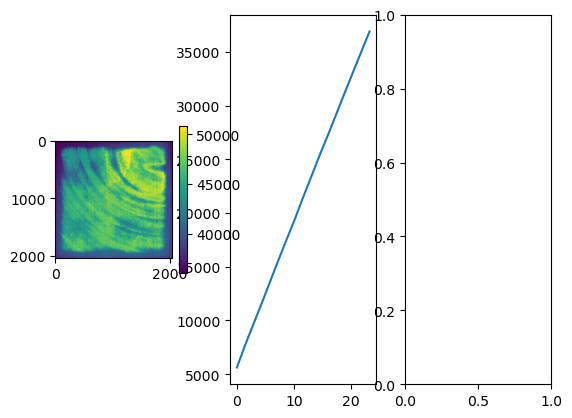

In [9]:
fig, axs = plt.subplots(1,3)
fig = ramp.show_frame(frame_num=-1, fig=fig, ax=axs[0], corr_refpix=True) # Frame to be chosen, default to 0
fig = ramp.show_pixramp(pixel_num=2040*10, fig=fig, ax=axs[1], corr_refpix=True)  # Example get one ramp for a single pixel. 
fig = ramp.show_pixramp(pixel_num=slice(4,6,1), fig=fig, ax=axs[2], corr_refpix=True)  # Example get one ramp for several pixel. 
# Small issue with axes sizes.
plt.tight_layout()
plt.show()

Fit ramp with chosen procedure : 
kwargs will depend on procedure (readnoise and gain can be plugged for Kubik for example) 

In [5]:
slope_lsq_leg = get_ramp_fit(ramp, fit_args=dict(deg=6), polytype='leg').reshape(2040,2040) # Using ref-corrected pixels only 'scicube'
slope_lsq = get_ramp_fit(ramp, fit_args=dict(deg=6), polytype='mono').reshape(2040,2040) #  Using ref-corrected pixels only 'scicube'
slope_kbk = get_ramp_fit(ramp, fit_procedure='Kubik')/np.diff(ramp.t_read)[0] #For OK units. Kubik works at the delta-group level. 


### Store output in SciExposure 
Name will probably change but should be the output with I/O

In [6]:
lsq_leg_img = SciExposure(data=slope_lsq_leg)
lsq_img = SciExposure(data=slope_lsq)
kbk_img = SciExposure(data=slope_kbk)

Plot : 

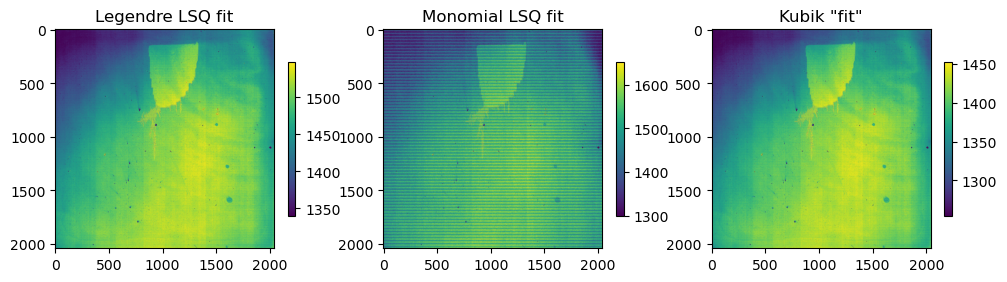

In [7]:
fig, axs = plt.subplots(1,3, figsize=(12,5))
axs[0].set_title('Legendre LSQ fit')
lsq_leg_img.show(ax=axs[0])
axs[1].set_title('Monomial LSQ fit')
lsq_img.show(ax=axs[1])
axs[2].set_title('Kubik "fit"')
kbk_img.show(ax=axs[2])
plt.show()